<a href="https://colab.research.google.com/github/dewi-ikrimah/RegeresiLinear_Kelas5B_Kelompok3/blob/main/RegresiLinear_Kelas5B_Kelompok3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Install library kaggle (biasanya sudah ada di Colab, tapi untuk memastikan)
!pip install -q kaggle

In [1]:
# 2. Mengatur Environment Variable untuk API Token
import os
import getpass

print("Silakan tempel (paste) API Token Kaggle Anda (dimulai dengan KGAT_...) dan tekan Enter:")
# getpass digunakan agar token yang Anda ketik tidak terlihat di layar
kaggle_token = getpass.getpass('KAGGLE_API_TOKEN: ')

# Menyetel environment variable agar library kaggle bisa membacanya
os.environ['KAGGLE_API_TOKEN'] = kaggle_token

print("\nOtentikasi API Kaggle Selesai!")

Silakan tempel (paste) API Token Kaggle Anda (dimulai dengan KGAT_...) dan tekan Enter:
KAGGLE_API_TOKEN: ··········

Otentikasi API Kaggle Selesai!


In [2]:
# ---------------------------------------------------------
# 3. MENGUNDUH DATASET CONTOH
# Perintah: kaggle datasets download -d [nama-pemilik/nama-dataset]
# ---------------------------------------------------------
print("Mengunduh dataset Medical Cost Personal Datasets...")
!kaggle datasets download -d mirichoi0218/insurance

Mengunduh dataset Medical Cost Personal Datasets...
Dataset URL: https://www.kaggle.com/datasets/mirichoi0218/insurance
License(s): DbCL-1.0
100% 16.0k/16.0k [00:00<00:00, 29.3MB/s]



In [3]:
# 4. Mengekstrak file ZIP hasil unduhan
# -q artinya 'quiet' (tanpa log ekstraksi yang panjang)
!unzip -q insurance.zip

print("Unduhan dan Ekstraksi Selesai!")

Unduhan dan Ekstraksi Selesai!


In [4]:
# ---------------------------------------------------------
# 5. MEMUAT DATA KE PANDAS (Langkah Awal EDA)
# ---------------------------------------------------------
import pandas as pd

# Membaca file CSV yang sudah diekstrak
# Sesuaikan nama file CSV dengan isi dari ZIP tersebut
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [5]:
# Menampilkan 5 baris pertama untuk memastikan koneksi dan load data berhasil
print("\n--- 5 Baris Pertama Dataset  Medical Cost Personal Datasets ---")
display(df.head())


--- 5 Baris Pertama Dataset  Medical Cost Personal Datasets ---


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## **Inspeksi Awal Data (Initial Data Inspection)**

 Tujuan Skrip

Skrip ini bertujuan untuk melakukan langkah-langkah awal dalam analisis data pada dataset 'Medical Cost Personal Datasets'. Secara spesifik, skrip ini meliputi:

1.  **Pengaturan Lingkungan**: Memastikan *library* Kaggle terinstal dan mengkonfigurasi token API Kaggle untuk akses dataset.
2.  **Pengunduhan dan Ekstraksi Data**: Mengunduh dataset 'Medical Cost Personal Datasets' dari Kaggle dan mengekstraknya ke dalam direktori lokal.
3.  **Pemuatan Data**: Memuat data dari file CSV yang sudah diekstrak ke dalam Pandas DataFrame untuk memudahkan manipulasi dan analisis.
4.  **Inspeksi Awal Data (Initial Data Inspection)**: Melakukan pemeriksaan awal terhadap struktur data, meliputi melihat beberapa baris pertama dan terakhir, mengetahui dimensi dataset (jumlah baris dan kolom), memeriksa tipe data setiap kolom, dan mendapatkan daftar nama kolom. Langkah ini penting untuk memahami karakteristik dasar data sebelum melakukan analisis lebih lanjut.

In [6]:
# Tampilkan 5 baris pertama data
print("--- 5 Baris Pertama Data ---")
display(df.head())

# Tampilkan 5 baris terakhir data (opsional, untuk memastikan data dimuat utuh)
print("\n--- 5 Baris Terakhir Data ---")
display(df.tail())

# Cek dimensi data (jumlah baris dan kolom)
print(f"\nDimensi dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

# Cek tipe data setiap kolom dan informasi penggunaan memori
print("\n--- Informasi Dataset (Tipe Data & Non-Null) ---")
df.info()

# Dapatkan nama-nama kolom
print("\n--- Daftar Nama Kolom ---")
print(df.columns.tolist())

--- 5 Baris Pertama Data ---


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



--- 5 Baris Terakhir Data ---


,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603



Dimensi dataset: 1338 baris, 7 kolom

--- Informasi Dataset (Tipe Data & Non-Null) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

--- Daftar Nama Kolom ---
['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges']


## Penjelasan Bagian-bagian Penting Skrip

Skrip ini terbagi menjadi beberapa bagian penting yang bekerja secara berurutan untuk mencapai tujuannya:

1.  **Instalasi dan Konfigurasi Kaggle API**: Ini adalah langkah persiapan awal yang memastikan lingkungan siap untuk berinteraksi dengan Kaggle. `!pip install -q kaggle` menginstal *library*, dan blok kode berikutnya (`import os`, `import getpass`, `os.environ[...]`) berfungsi untuk mengamankan dan mengesahkan akses ke akun Kaggle Anda menggunakan token API.

2.  **Pengunduhan dan Ekstraksi Dataset**: Setelah Kaggle API siap, skrip menggunakan perintah `!kaggle datasets download -d mirichoi0218/insurance` untuk mengunduh dataset yang diinginkan. Kemudian, `!unzip -q ...` bertanggung jawab untuk mengekstrak file ZIP yang terunduh, membuatnya tersedia dalam format yang dapat dibaca.

3.  **Pemuatan Data ke Pandas DataFrame**: Bagian ini adalah inti dari manipulasi data. `import pandas as pd` mengimpor *library* Pandas, dan `df = pd.read_csv('insurance.csv')` memuat data dari file CSV yang telah diekstrak ke dalam sebuah objek DataFrame (`df`). DataFrame adalah struktur data tabular yang sangat powerful di Pandas untuk analisis data.

4.  **Inspeksi Awal Data**: Setelah data dimuat, serangkaian perintah seperti `display(df.head())`, `display(df.tail())`, `df.shape`, `df.info()`, dan `df.columns.tolist()` digunakan untuk mendapatkan gambaran cepat tentang isi, ukuran, tipe data, dan kolom-kolom yang ada dalam dataset. Ini adalah langkah krusial dalam *Exploratory Data Analysis* (EDA) untuk mengidentifikasi potensi masalah atau memahami karakteristik data.

## **Pengecekan Kualitas Data Dasar** (Basic Data Quality Checks)

--- Pengecekan Missing Values ---


,Jumlah Missing,Persentase (%)


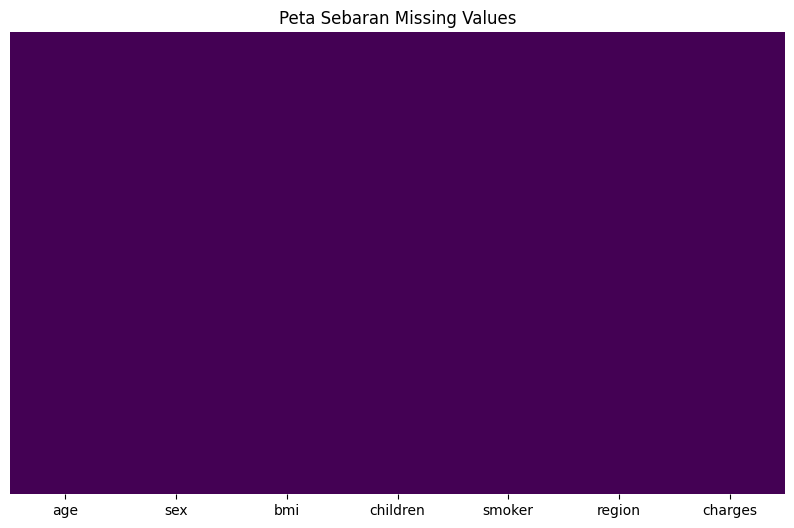


--- Pengecekan Data Duplikat ---
Jumlah baris duplikat identik: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Pengecekan Missing Values ---")
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_table = pd.concat([missing_data, missing_percent], axis=1, keys=['Jumlah Missing', 'Persentase (%)'])
# Tampilkan hanya kolom yang memiliki missing value
display(missing_table[missing_table['Jumlah Missing'] > 0])

# Visualisasi Missing Values (Menggunakan Heatmap seaborn)
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.title('Peta Sebaran Missing Values')
plt.show()

print("\n--- Pengecekan Data Duplikat ---")
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat identik: {jumlah_duplikat}")
# Jika ada, Anda bisa menampilkan contoh duplikatnya dengan mengaktifkan baris di bawah:
if jumlah_duplikat > 0:
    display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))

### Ringkasan Pengecekan Kualitas Data

Berdasarkan pemeriksaan kualitas data:

* **Tidak ada missing values:** Tidak ditemukan nilai yang hilang pada kolom mana pun.
* **Terdapat 1 baris duplikat:** Ditemukan 1 baris duplikat, yaitu 2 baris yang identik. Duplikat tersebut kemudian dihapus sebelum tahap EDA dan pemodelan.
* Setelah proses cleaning, dataset yang digunakan untuk analisis berjumlah **1.337 baris**.


## **Pembersihan Data Duplikat**

In [8]:
# Menghapus baris duplikat yang ditemukan pada dataset
print(f"Jumlah baris sebelum dibersihkan: {df.shape[0]}")

# Proses pembersihan duplikat
df = df.drop_duplicates().reset_index(drop=True)

print(f"Jumlah baris setelah duplikat dihapus: {df.shape[0]}")
print("Data kini sudah bersih dan siap digunakan untuk tahap analisis serta visualisasi selanjutnya.")

Jumlah baris sebelum dibersihkan: 1338
Jumlah baris setelah duplikat dihapus: 1337
Data kini sudah bersih dan siap digunakan untuk tahap analisis serta visualisasi selanjutnya.


Setelah 1 baris duplikat dihapus, dataset awal berisi 1.338 baris dan 7 kolom, dataset yang digunakan untuk analisis berjumlah **1.337 baris** dan tidak memiliki *missing values*. Data yang sudah dibersihkan kemudian digunakan secara konsisten untuk tahap EDA, preprocessing, dan pemodelan.


## **Statistik Deskriptif (Descriptive Statistics)**

In [9]:
print("--- Statistik Deskriptif untuk Kolom Numerik ---")
display(df.describe())

print("\n--- Statistik Deskriptif untuk Kolom Kategori (Objek) ---")
display(df.describe(include='object'))

--- Statistik Deskriptif untuk Kolom Numerik ---


,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010



--- Statistik Deskriptif untuk Kolom Kategori (Objek) ---


,sex,smoker,region
count,1337,1337,1337
unique,2,2,4
top,male,no,southeast
freq,675,1063,364


### Ringkasan Statistik Deskriptif

Setelah duplikat dihapus, statistik deskriptif menunjukkan karakteristik berikut pada **1.337 baris data**:

**Kolom numerik (`age`, `bmi`, `children`, `charges`):**
* **Count:** 1.337 pada setiap kolom numerik, menunjukkan tidak ada nilai yang hilang.
* **Mean:** usia rata-rata sekitar **39,22** tahun, BMI **30,66**, jumlah anak **1,10**, dan `charges` sekitar **13.279,12**.
* **Std:** standar deviasi `age` sekitar **14,04**, `bmi` **6,10**, `children` **1,21**, dan `charges` **12.110,36**, sehingga variasi `charges` cukup besar.
* **Median `charges`:** sekitar **9.386,16**, lebih rendah daripada mean sehingga distribusi `charges` menunjukkan kecenderungan *right-skewed*.
* **Minimum–maksimum:** `age` 18–64, `bmi` 15,96–53,13, `children` 0–5, dan `charges` 1.121,87–63.770,43.

**Kolom kategorikal (`sex`, `smoker`, `region`):**
* `sex` memiliki **2 kategori**, dengan `male` sebanyak **675** dan `female` **662**.
* `smoker` memiliki **2 kategori**, yaitu `no` sebanyak **1.063** dan `yes` **274**.
* `region` memiliki **4 kategori**, dengan `southeast` sebagai kategori terbanyak sebanyak **364** data.

Statistik deskriptif ini digunakan sebagai dasar untuk melanjutkan analisis distribusi, hubungan antarvariabel, dan pemodelan regresi.


## **Analisis Univariat (Univariate Analysis)**

### Analisis Univariat untuk Kolom Numerik ###


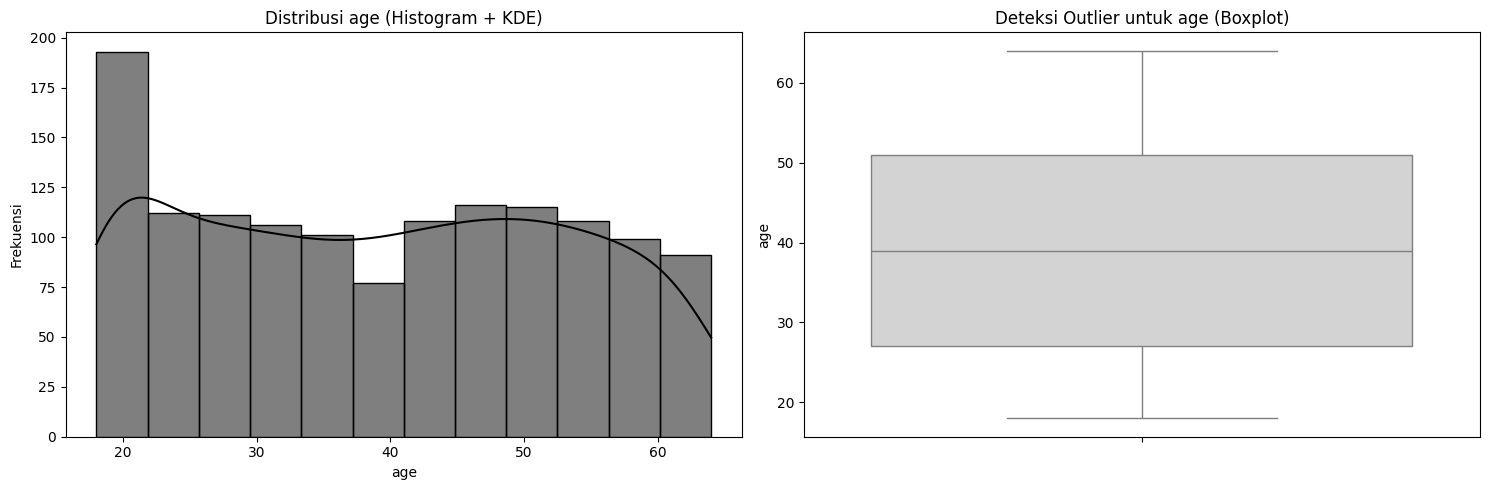

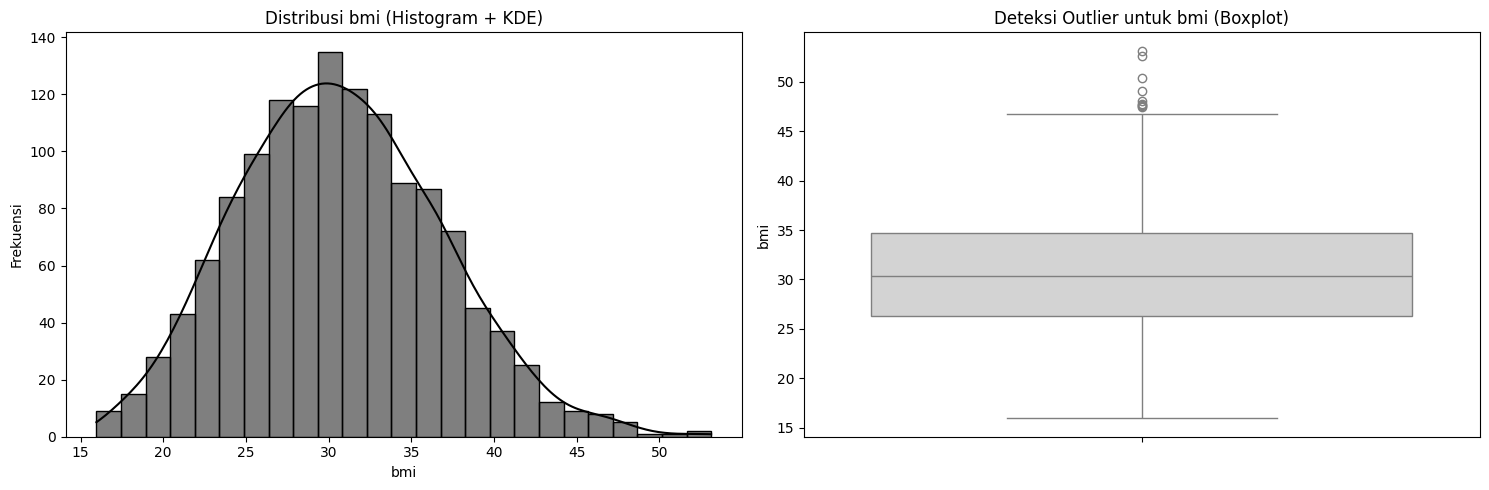

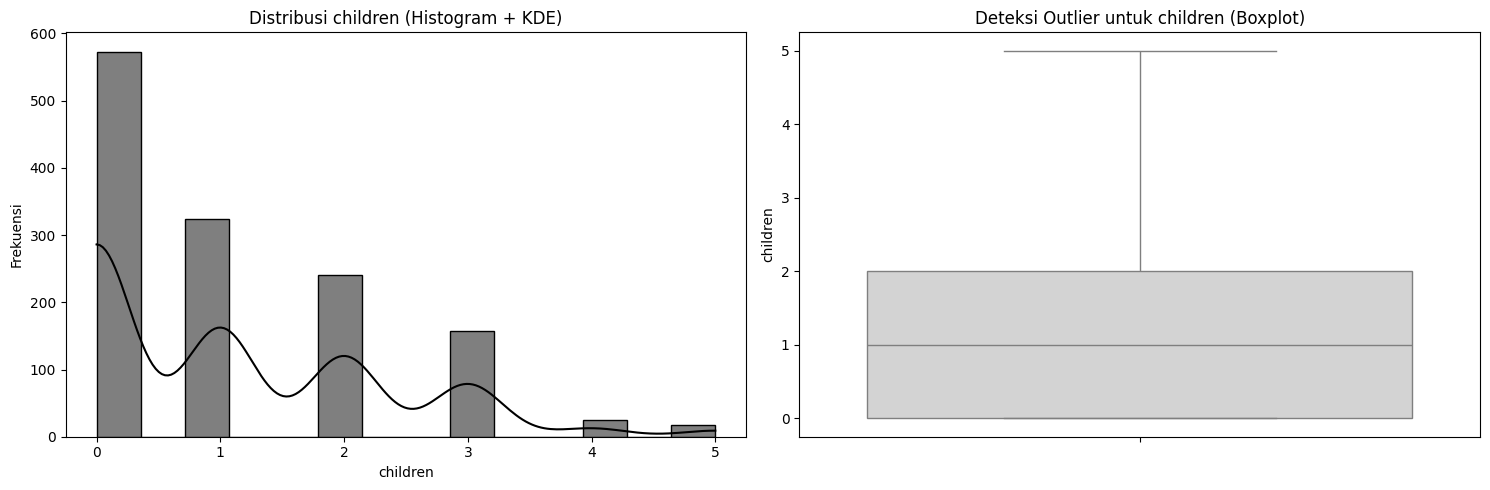

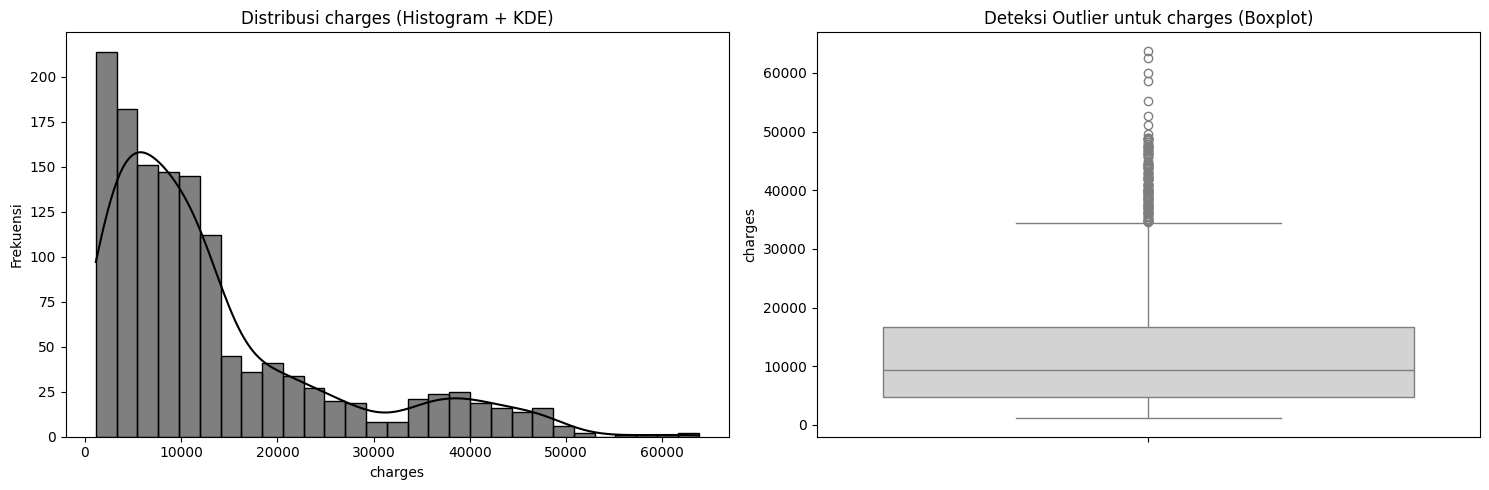


### Analisis Univariat untuk Kolom Kategorikal ###


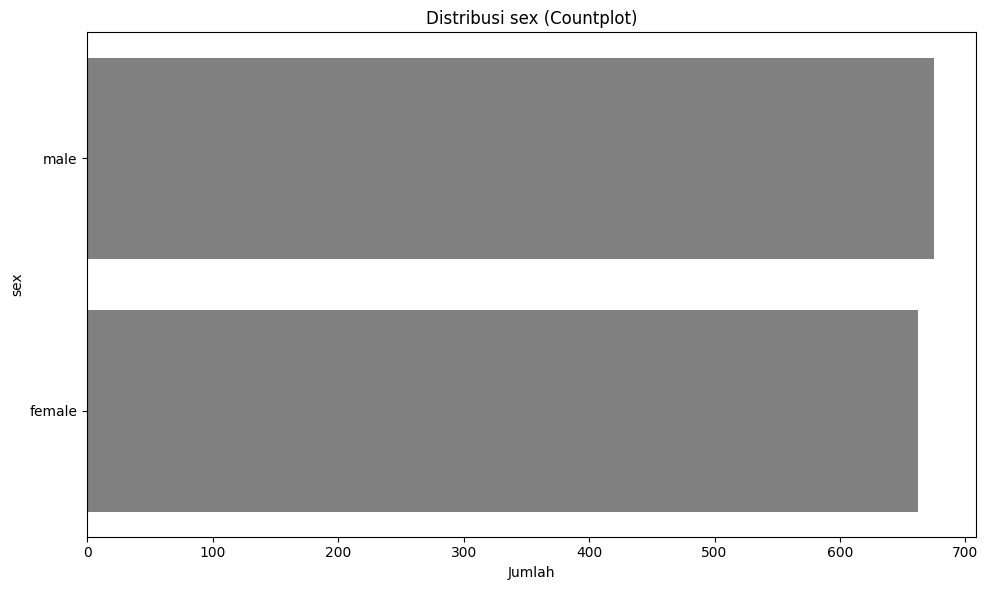

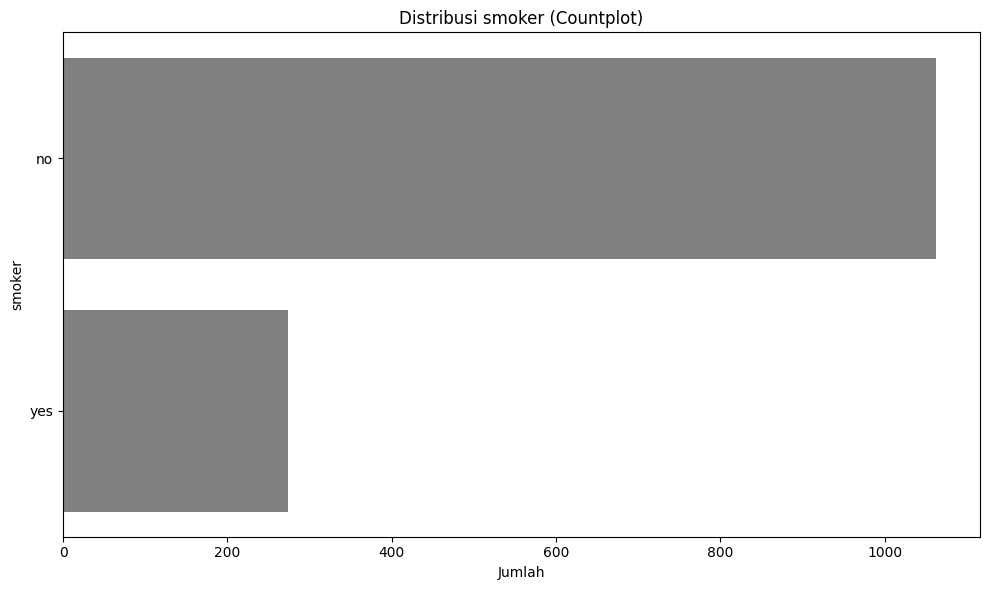

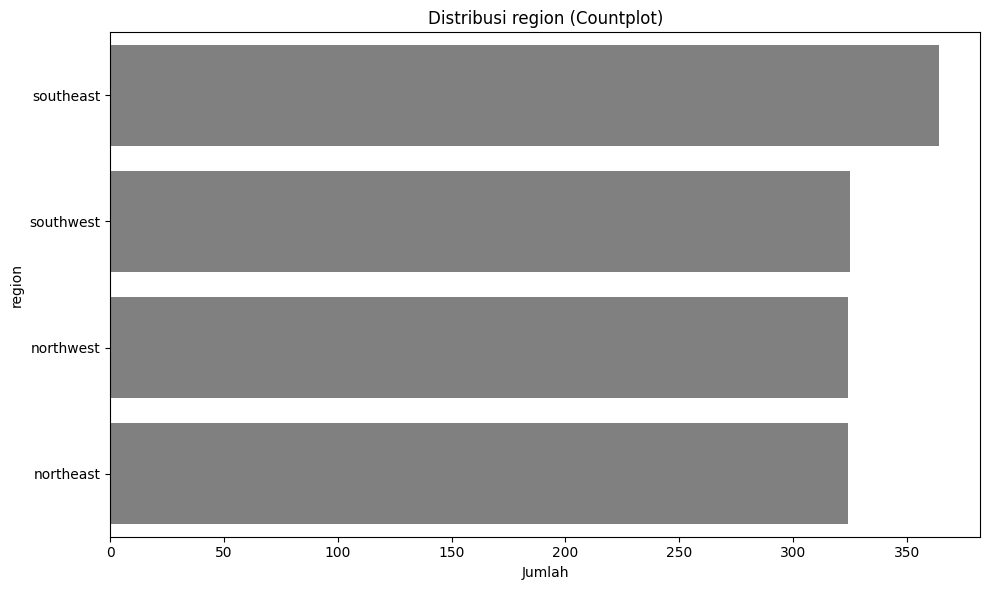

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Memisahkan kolom numerik dan kategorikal
kolom_numerik = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
kolom_kategorikal = df.select_dtypes(include=['object']).columns.tolist()

print("### Analisis Univariat untuk Kolom Numerik ###")
for kolom in kolom_numerik:
    plt.figure(figsize=(15, 5))

    # Histplot dengan KDE
    plt.subplot(1, 2, 1) # 1 baris, 2 kolom, plot pertama
    sns.histplot(df[kolom], kde=True, color='black')
    plt.title(f'Distribusi {kolom} (Histogram + KDE)')
    plt.xlabel(kolom)
    plt.ylabel('Frekuensi')

    # Boxplot untuk Outliers
    plt.subplot(1, 2, 2) # 1 baris, 2 kolom, plot kedua
    sns.boxplot(y=df[kolom], color='lightgray')
    plt.title(f'Deteksi Outlier untuk {kolom} (Boxplot)')
    plt.ylabel(kolom)

    plt.tight_layout()
    plt.show()

print("\n### Analisis Univariat untuk Kolom Kategorikal ###")
for kolom in kolom_kategorikal:
    plt.figure(figsize=(10, 6))
    # Countplot dengan pengurutan berdasarkan frekuensi
    sns.countplot(y=df[kolom], order=df[kolom].value_counts().index, color='gray')
    plt.title(f'Distribusi {kolom} (Countplot)')
    plt.xlabel('Jumlah')
    plt.ylabel(kolom)
    plt.tight_layout()
    plt.show()


### Ringkasan Hasil Analisis Univariat

Berdasarkan histogram, KDE, boxplot, dan countplot pada data yang sudah dibersihkan:

**1. Variabel numerik (`age`, `bmi`, `children`, `charges`)**
* `age` tersebar pada rentang 18–64 tahun.
* `bmi` terpusat di sekitar nilai 30 dan memiliki beberapa nilai tinggi hingga **53,13**.
* `children` lebih banyak berada pada nilai 0–1, sedangkan jumlah 4–5 relatif sedikit.
* `charges` menunjukkan distribusi **miring ke kanan (*right-skewed*)** dengan sejumlah nilai biaya yang sangat tinggi hingga sekitar **63.770,43**.

**2. Variabel kategorikal (`sex`, `smoker`, `region`)**
* `sex` relatif seimbang: `male` 675 data dan `female` 662 data.
* `smoker` didominasi kategori `no` (**1.063 data; sekitar 79,5%**), sedangkan `yes` sebanyak **274 data; sekitar 20,5%**.
* `region` terdiri dari empat wilayah, dengan `southeast` sebagai kategori terbanyak (**364 data; sekitar 27,2%**).

Analisis univariat memberikan gambaran awal tentang distribusi, komposisi kategori, dan keberadaan nilai ekstrem sebelum hubungan antarvariabel dianalisis lebih lanjut.


### **Analisis Bivariat & Multivariat (Bivariate & Multivariate Analysis)**

### 1. Korelasi Variabel Numerik ###


,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


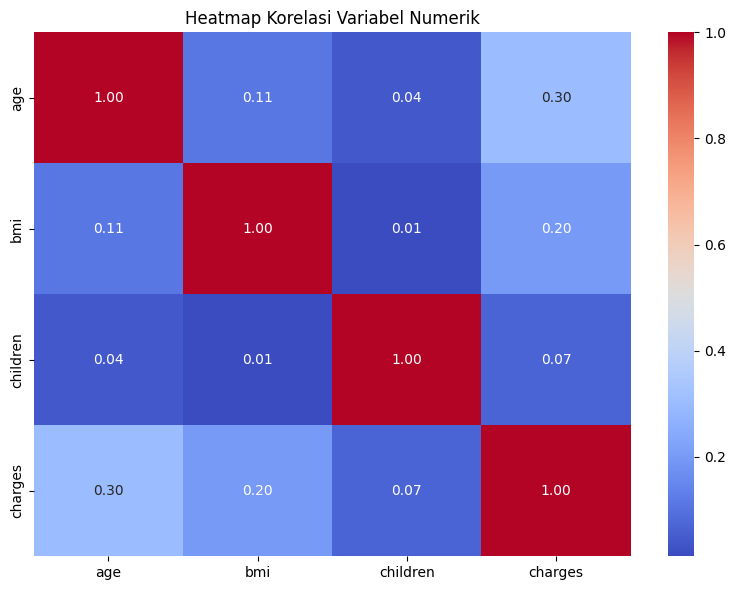


### 2. Rata-rata Charges Berdasarkan Variabel Kategorikal ###

Rata-rata charges berdasarkan smoker:


,charges
smoker,
no,8440.66
yes,32050.23


Rata-rata charges berdasarkan region:


,charges
region,
northeast,13406.38
northwest,12450.84
southeast,14735.41
southwest,12346.94


Rata-rata charges berdasarkan sex:


,charges
sex,
female,12569.58
male,13975.00



### 3. Scatter Plot Age dan BMI terhadap Charges ###


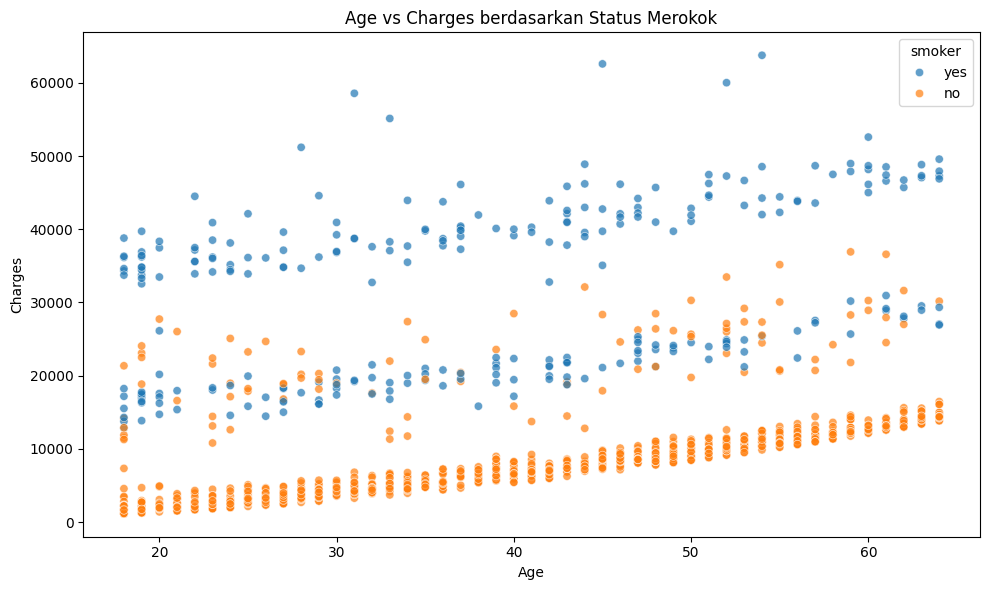

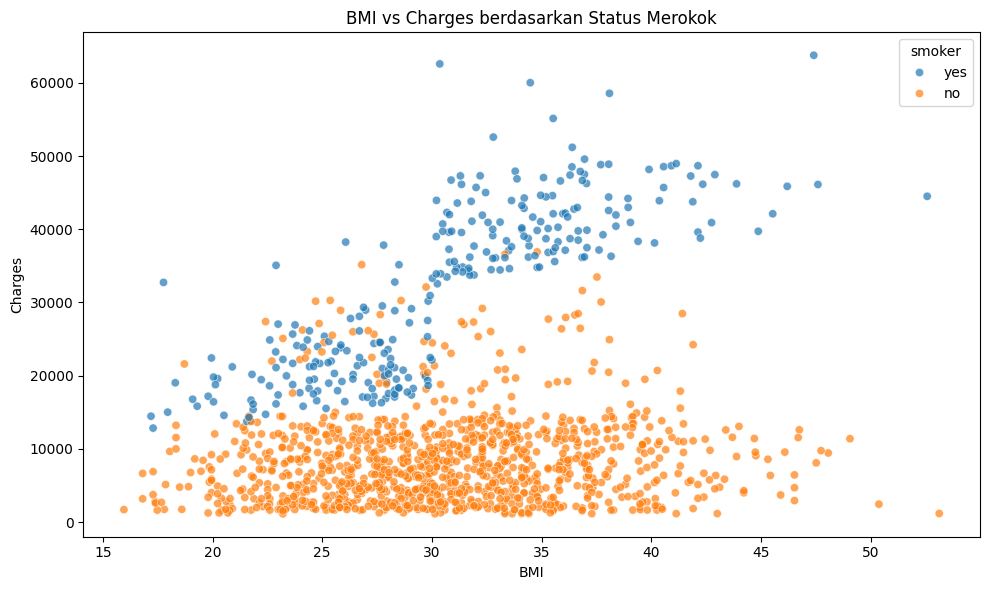


### 4. Boxplot Charges Berdasarkan Kategori ###


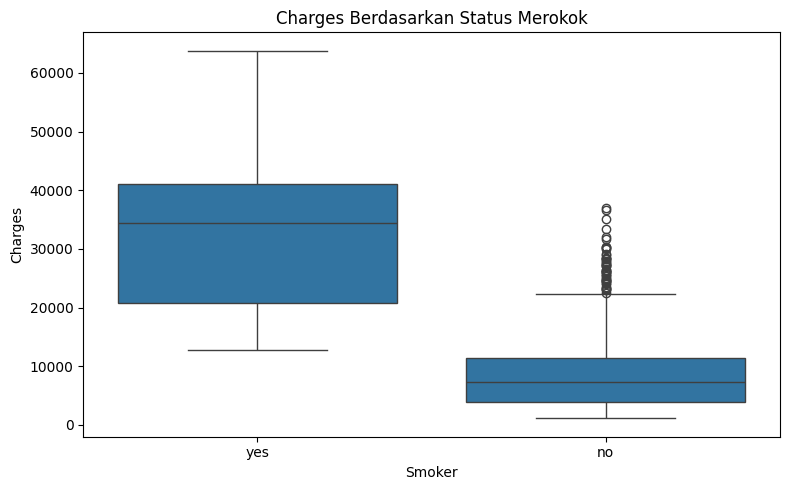

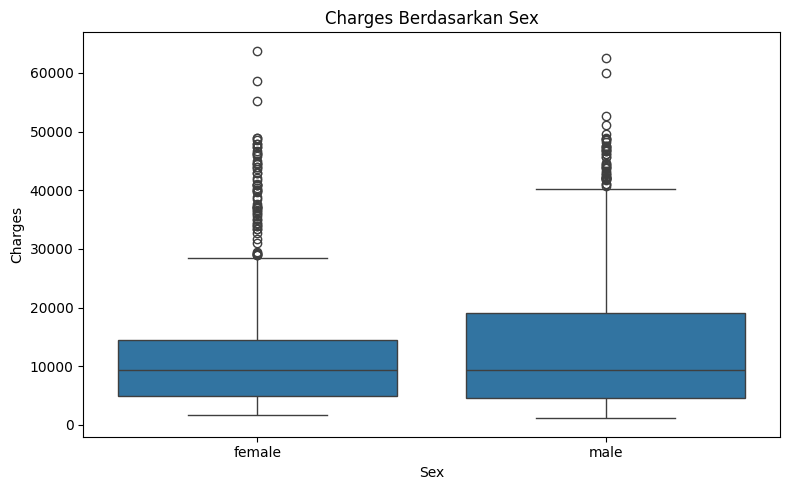

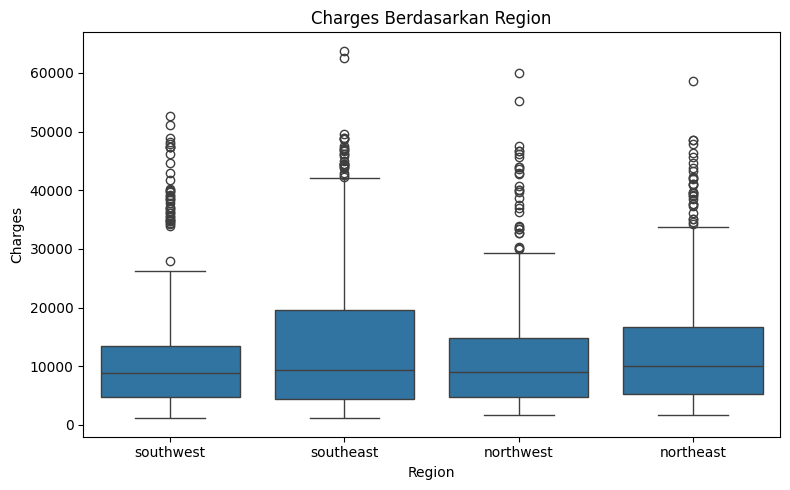

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Catatan: df sudah dibersihkan pada tahap sebelumnya (1.337 baris).
# Jangan memuat ulang insurance.csv agar EDA tetap menggunakan data bersih.

kolom_numerik_eda = ['age', 'bmi', 'children', 'charges']

print("### 1. Korelasi Variabel Numerik ###")
correlation_matrix = df[kolom_numerik_eda].corr()
display(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap Korelasi Variabel Numerik')
plt.tight_layout()
plt.show()

print("\n### 2. Rata-rata Charges Berdasarkan Variabel Kategorikal ###")
print("\nRata-rata charges berdasarkan smoker:")
display(df.groupby('smoker')['charges'].mean().round(2))

print("Rata-rata charges berdasarkan region:")
display(df.groupby('region')['charges'].mean().round(2))

print("Rata-rata charges berdasarkan sex:")
display(df.groupby('sex')['charges'].mean().round(2))

print("\n### 3. Scatter Plot Age dan BMI terhadap Charges ###")

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', alpha=0.7)
plt.title('Age vs Charges berdasarkan Status Merokok')
plt.xlabel('Age')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', alpha=0.7)
plt.title('BMI vs Charges berdasarkan Status Merokok')
plt.xlabel('BMI')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

print("\n### 4. Boxplot Charges Berdasarkan Kategori ###")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title('Charges Berdasarkan Status Merokok')
plt.xlabel('Smoker')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='sex', y='charges')
plt.title('Charges Berdasarkan Sex')
plt.xlabel('Sex')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='region', y='charges')
plt.title('Charges Berdasarkan Region')
plt.xlabel('Region')
plt.ylabel('Charges')
plt.tight_layout()
plt.show()


### Ringkasan Hasil Analisis Bivariat dan Multivariat

Berdasarkan analisis pada **data yang sudah dibersihkan (1.337 baris)**:

**1. Korelasi dengan `charges`**
* `age` memiliki korelasi positif sekitar **0,30** terhadap `charges`.
* `bmi` memiliki korelasi positif sekitar **0,20** terhadap `charges`.
* `children` memiliki korelasi yang relatif lemah, sekitar **0,07**.
* Korelasi ini menunjukkan arah dan kekuatan hubungan linear, bukan hubungan sebab-akibat.

**2. Status merokok (`smoker`)**
* Kelompok `smoker = yes` memiliki distribusi `charges` yang jauh lebih tinggi daripada `smoker = no`.
* Rata-rata `charges` sekitar **8.440,66** untuk non-smoker dan **32.050,23** untuk smoker.
* Pola ini merupakan perbedaan yang paling jelas dalam EDA.

**3. `sex` dan `region`**
* Perbedaan `charges` berdasarkan `sex` relatif lebih kecil dibandingkan perbedaan berdasarkan `smoker`.
* Terdapat perbedaan rata-rata `charges` antarwilayah, tetapi pola tersebut juga tidak sejelas perbedaan berdasarkan `smoker`.

**4. Scatter plot**
* `age` dan `bmi` sama-sama menunjukkan kecenderungan hubungan positif dengan `charges`.
* Pewarnaan berdasarkan `smoker` memperlihatkan pemisahan kelompok biaya yang jelas antara smoker dan non-smoker.

Secara keseluruhan, EDA menunjukkan bahwa **status merokok merupakan pembeda paling jelas dalam distribusi `charges`**, sementara `age` dan `bmi` menunjukkan hubungan positif dan `children` relatif lemah. Temuan ini digunakan sebagai dasar untuk tahap pemodelan regresi dan tidak dimaksudkan sebagai bukti hubungan sebab-akibat.


## **Catatan Kesimpulan dan Langkah Selanjutnya (Insights & Next Steps)**

### Ringkasan Temuan Utama dari Eksplorasi Data (EDA)

Berdasarkan analisis pada dataset **Medical Cost Personal Datasets** (`insurance.csv`), diperoleh temuan berikut:

1. **Kualitas data:** Setelah 1 baris duplikat dihapus, dataset berjumlah **1.337 baris** dan tidak memiliki *missing values*.
2. **Status merokok:** `smoker` menunjukkan perbedaan `charges` yang paling jelas. Rata-rata `charges` sekitar **8.440,66** pada non-smoker dan **32.050,23** pada smoker.
3. **Age dan BMI:** Keduanya menunjukkan hubungan positif dengan `charges`, masing-masing memiliki korelasi sekitar **0,30** dan **0,20**.
4. **Charges:** Distribusi `charges` miring ke kanan (*right-skewed*) dan memiliki beberapa nilai tinggi hingga sekitar **63.770,43**.
5. **Sex:** Perbedaan `charges` berdasarkan `sex` relatif lebih kecil dibandingkan pola berdasarkan `smoker`.
6. **Region:** Terdapat perbedaan antarwilayah, tetapi tidak sejelas perbedaan berdasarkan `smoker`.
7. **Children:** Hubungannya dengan `charges` relatif lemah, dengan korelasi sekitar **0,07**.
8. **BMI:** Terdapat beberapa nilai BMI tinggi hingga **53,13** yang perlu diperhatikan saat membaca distribusi data.

### Langkah Selanjutnya

* **Pemodelan regresi:** Menggunakan seluruh fitur yang tersedia untuk memprediksi `charges`.
* **Evaluasi model:** Menggunakan MAE, MSE, RMSE, dan R².
* **Analisis residual:** Memeriksa pola kesalahan prediksi dan membandingkan nilai aktual dengan nilai prediksi.


## **Preprocessing**

**Langkah 1: Menyiapkan Fitur dan Target**

In [13]:
# Memastikan library yang diperlukan tersedia untuk preprocessing dan pemodelan
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Data sudah dibersihkan pada tahap sebelumnya.
# Di sini hanya memisahkan fitur (X) dan target (y).
X = df.drop(columns=['charges'])
y = df['charges']

print("Jumlah data bersih:", len(df))
print("Fitur (X) shape:", X.shape)
print("Target (y) shape:", y.shape)


Jumlah data bersih: 1337
Fitur (X) shape: (1337, 6)
Target (y) shape: (1337,)


## **Penjelasan:**

Tahap cleaning sudah dilakukan sebelum EDA. Karena itu, pada bagian preprocessing tidak dilakukan `drop_duplicates()` lagi agar proses pembersihan tidak berulang.

Variabel `X` berisi enam fitur (`age`, `sex`, `bmi`, `children`, `smoker`, dan `region`), sedangkan `y` berisi target `charges`.


- **Jumlah data bersih:** 1.337 baris.
- **Fitur (X):** berukuran `(1337, 6)`, yaitu enam variabel input setelah `charges` dipisahkan.
- **Target (y):** berukuran `(1337,)`, yaitu satu nilai `charges` untuk setiap baris data.

Dengan demikian, data yang masuk ke preprocessing dan pemodelan konsisten dengan data yang telah digunakan pada tahap EDA.


### **Langkah 2: Menentukan Jenis Kolom & Membuat Preprocessor**

In [15]:
# Menentukan fitur numerik dan kategorikal
kolom_num = ['age', 'bmi', 'children']
kolom_kat = ['sex', 'smoker', 'region']

print("Kolom Numerik:", kolom_num)
print("Kolom Kategorikal:", kolom_kat)

# Preprocessing dilakukan di dalam Pipeline agar transformasi hanya dipelajari
# dari data training dan diterapkan konsisten pada data testing.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), kolom_num),
        ('cat', OneHotEncoder(handle_unknown='ignore'), kolom_kat)
    ]
)


Kolom Numerik: ['age', 'bmi', 'children']
Kolom Kategorikal: ['sex', 'smoker', 'region']


### Menentukan Fitur Numerik dan Kategorikal

Fitur yang digunakan terdiri dari dua kelompok:

**Fitur numerik:** `age`, `bmi`, dan `children` → distandardisasi menggunakan **StandardScaler**.

**Fitur kategorikal:** `sex`, `smoker`, dan `region` → diubah menjadi representasi numerik menggunakan **One-Hot Encoding**.

Preprocessing tersebut kemudian digabungkan dengan model regresi menggunakan **Pipeline** agar proses transformasi konsisten antara data training dan testing.


## **Langkah 3: Membagi Data Latih dan Uji (Train-Test Split)**

In [16]:
# Membagi data menjadi 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Ukuran Data Latih (X_train): {X_train.shape}")
print(f"Ukuran Data Uji (X_test): {X_test.shape}")


Ukuran Data Latih (X_train): (1069, 6)
Ukuran Data Uji (X_test): (268, 6)


### Pembagian Data Training dan Testing

Dataset dibagi menjadi data **training** dan **testing** dengan perbandingan **80:20** menggunakan `random_state=42`.

Hasil pembagian adalah:
* **1.069 data training**
* **268 data testing**

Data testing tidak digunakan dalam proses pelatihan sehingga dapat digunakan untuk mengevaluasi kemampuan model pada data yang belum dilihat model.


## **Regresi**

Model berhasil dilatih.

10 hasil prediksi pertama:
[ 8143.69388412  5737.11568259 14369.31487618 31745.51363586
  8962.38665706 13149.72235307 30446.76067941  1453.28881259
 10633.01840233 11318.94379361]

HASIL EVALUASI MODEL
MAE  : 4177.05
MSE  : 35478020.68
RMSE : 5956.34
R²   : 0.807


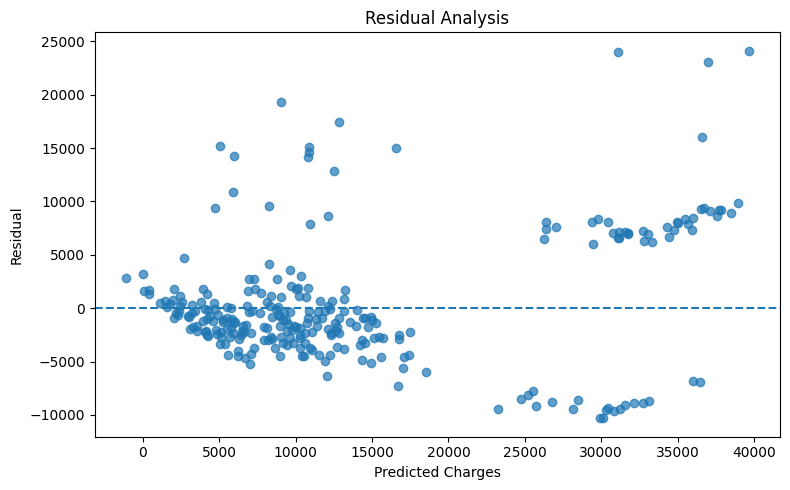

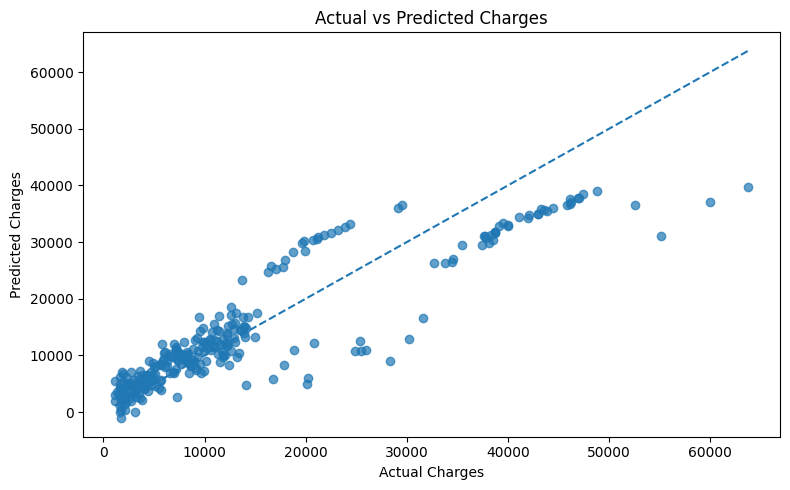

In [17]:
# =========================================================
# REGRESI LINEAR
# =========================================================

# Membuat model dengan preprocessing dan Linear Regression dalam satu Pipeline.
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

# Melatih model hanya pada data training.
model.fit(X_train, y_train)
print("Model berhasil dilatih.")

# Melakukan prediksi pada data testing.
y_pred = model.predict(X_test)

print("\n10 hasil prediksi pertama:")
print(y_pred[:10])

# =========================================================
# EVALUASI MODEL
# =========================================================

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\n====================================")
print("HASIL EVALUASI MODEL")
print("====================================")
print("MAE  :", round(mae, 2))
print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("R²   :", round(r2, 3))

# =========================================================
# ANALISIS RESIDUAL
# =========================================================

residual = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residual, alpha=0.7)
plt.axhline(y=0, linestyle='--')
plt.xlabel('Predicted Charges')
plt.ylabel('Residual')
plt.title('Residual Analysis')
plt.tight_layout()
plt.show()

# =========================================================
# ACTUAL VS PREDICTED
# =========================================================

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')
plt.tight_layout()
plt.show()


## Penjelasan Hasil Regresi Linear

### 1. Fitur dan Target

Seluruh variabel selain `charges` digunakan sebagai fitur, yaitu `age`, `sex`, `bmi`, `children`, `smoker`, dan `region`. Target yang diprediksi adalah `charges`.

### 2. Pembagian Data

Data dibagi menjadi **80% training** dan **20% testing**, menghasilkan **1.069 data training** dan **268 data testing**.

### 3. Preprocessing

Fitur numerik (`age`, `bmi`, `children`) distandardisasi menggunakan **StandardScaler**, sedangkan fitur kategorikal (`sex`, `smoker`, `region`) diubah menggunakan **One-Hot Encoding**.

### 4. Pelatihan dan Prediksi

Preprocessing dan **Linear Regression** digabungkan dalam satu **Pipeline**. Model dilatih menggunakan data training dan menghasilkan prediksi `charges` pada data testing.

### 5. Evaluasi Model

Model dievaluasi dengan MAE, MSE, RMSE, dan R². Pada data pengujian diperoleh:
* **MAE = 4.177,05**
* **MSE = 35.478.020,68**
* **RMSE = 5.956,34**
* **R² = 0,807**

Nilai R² menunjukkan bahwa sekitar **80,7% variasi `charges` pada data pengujian dapat dijelaskan oleh model**.

### 6. Analisis Residual

Residual dihitung sebagai **nilai aktual − nilai prediksi**. Residual positif berarti model melakukan *underprediction*, sedangkan residual negatif berarti model melakukan *overprediction*. Grafik residual digunakan untuk melihat pola kesalahan prediksi.

### 7. Actual vs Predicted

Grafik **Actual vs Predicted Charges** membandingkan nilai aktual dengan hasil prediksi. Garis diagonal merupakan kondisi ideal ketika prediksi sama dengan nilai aktual; titik yang lebih dekat ke garis menunjukkan prediksi yang lebih dekat dengan nilai aktual.


### Interpretasi Hasil Evaluasi Model

Model **Linear Regression** menghasilkan **MAE 4.177,05**, **RMSE 5.956,34**, dan **R² 0,807** pada data pengujian.

* **MAE** menunjukkan rata-rata besar kesalahan absolut prediksi sekitar 4.177,05.
* **MSE** memberikan penalti lebih besar pada kesalahan yang besar karena error dikuadratkan.
* **RMSE** menyatakan besarnya kesalahan prediksi dalam satuan `charges`.
* **R²** sebesar 0,807 berarti sekitar 80,7% variasi `charges` pada data uji dapat dijelaskan oleh model.

Secara keseluruhan, hasil ini menunjukkan bahwa Linear Regression dapat digunakan sebagai **model regresi awal** untuk dataset ini, meskipun masih terdapat error prediksi yang dapat dikembangkan pada tahap berikutnya.


### **Kesimpulan**

Berdasarkan seluruh proses EDA hingga pemodelan pada dataset **Medical Cost Personal Datasets**, diperoleh kesimpulan berikut:

1. Dataset awal berisi **1.338 baris dan 7 kolom**. Ditemukan **1 baris duplikat** dan tidak terdapat *missing values*. Setelah cleaning, data yang digunakan berjumlah **1.337 baris**.
2. Pada tahap EDA, `smoker` menunjukkan **perbedaan `charges` yang paling jelas**. Kelompok smoker memiliki rata-rata `charges` sekitar **32.050,23**, sedangkan non-smoker sekitar **8.440,66**.
3. `age` dan `bmi` menunjukkan hubungan positif dengan `charges`, sedangkan `children` memiliki hubungan yang relatif lemah.
4. Distribusi `charges` cenderung *right-skewed* dan memiliki beberapa nilai tinggi hingga sekitar **63.770,43**.
5. Pada preprocessing, fitur numerik distandardisasi dengan **StandardScaler** dan fitur kategorikal diubah menggunakan **One-Hot Encoding** dalam satu **Pipeline**.
6. Data dibagi menjadi **1.069 training** dan **268 testing** dengan rasio 80:20 dan `random_state=42`.
7. Model **Linear Regression** menghasilkan **MAE 4.177,05**, **MSE 35.478.020,68**, **RMSE 5.956,34**, dan **R² 0,807**.
8. Analisis residual serta **Actual vs Predicted** digunakan untuk melihat pola dan besarnya kesalahan prediksi.

Secara keseluruhan, notebook telah menjalankan alur **cleaning → EDA → preprocessing → regresi → evaluasi** secara konsisten. Temuan EDA menunjukkan pola dan hubungan dalam data, bukan bukti hubungan sebab-akibat.
